<a href="https://colab.research.google.com/github/Ridhman07/IP-Lab-Assignments/blob/main/Assignment%204.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

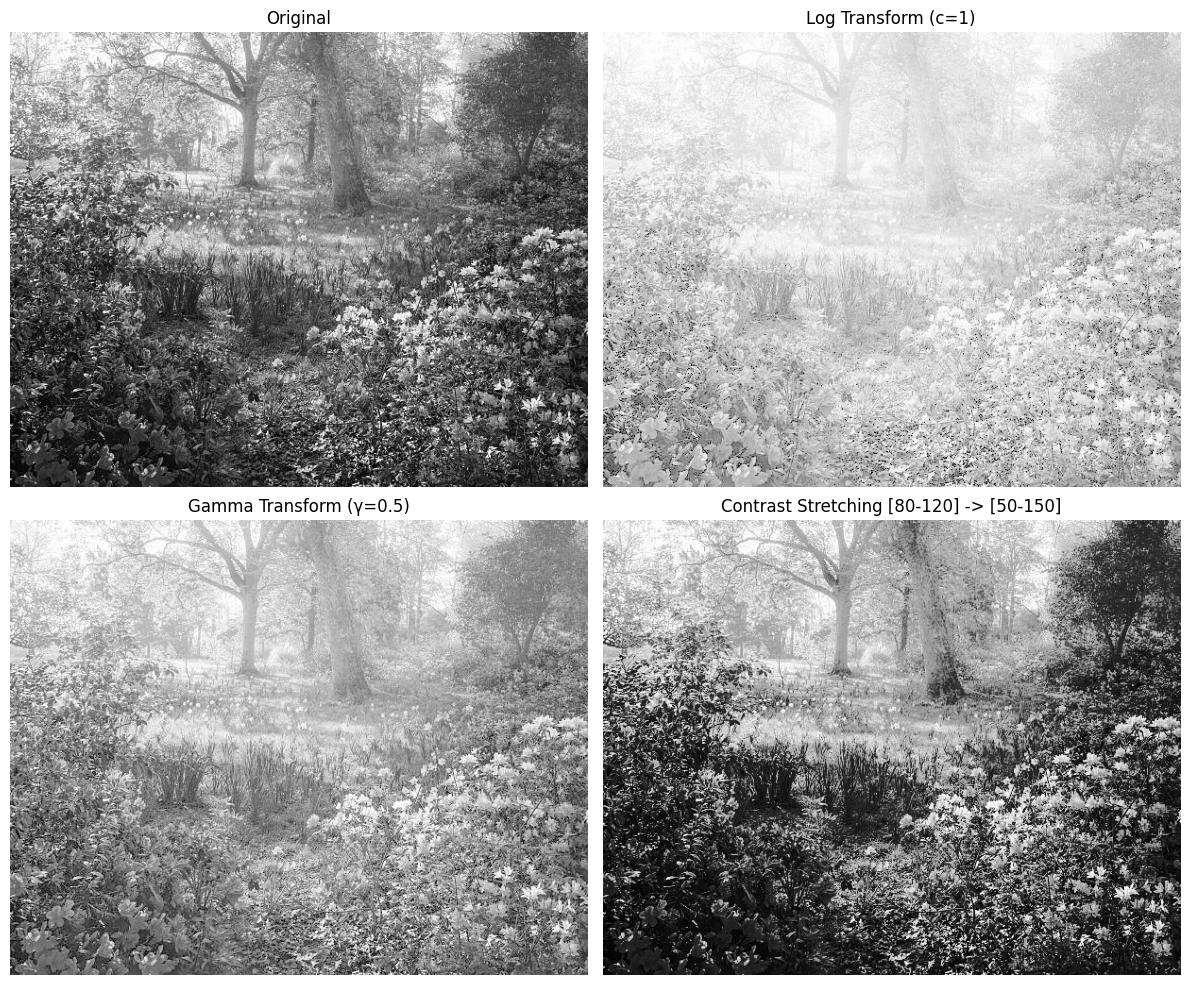

In [5]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Paste your copied path here
image_path = "/content/image.jpg"

# Verification check
if not os.path.exists(image_path):
    raise FileNotFoundError(f"Image not found at '{image_path}'. Check the Files panel on the left.")

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError(f"OpenCV could not decode the image at '{image_path}'. Ensure it is a valid image format.")

# 1. Log Transform: s = c * log(1 + r)
c_log = 1.0
log_transformed = c_log * np.log1p(img.astype(np.float64))
log_transformed = ((log_transformed / log_transformed.max()) * 255).astype(np.uint8)

# 2. Power Law / Gamma Transform: s = c * (r ^ gamma)
gamma = 0.5
c_gamma = 1.0
img_norm = img.astype(np.float64) / 255.0
gamma_transformed = c_gamma * np.power(img_norm, gamma)
gamma_transformed = np.clip(gamma_transformed * 255.0, 0, 255).astype(np.uint8)

# 3. Contrast Stretching (r1=80, r2=120 -> s1=50, s2=150)
r1, r2 = 80.0, 120.0
s1, s2 = 50.0, 150.0

stretched = np.zeros_like(img, dtype=np.float64)
mask1 = img < r1
mask2 = (img >= r1) & (img <= r2)
mask3 = img > r2

stretched[mask1] = (s1 / r1) * img[mask1] if r1 > 0 else 0
stretched[mask2] = ((s2 - s1) / (r2 - r1)) * (img[mask2] - r1) + s1
stretched[mask3] = ((255.0 - s2) / (255.0 - r2)) * (img[mask3] - r2) + s2
stretched = np.clip(stretched, 0, 255).astype(np.uint8)

# Display outputs
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes[0, 0].imshow(img, cmap='gray')
axes[0, 0].set_title("Original")
axes[0, 0].axis('off')

axes[0, 1].imshow(log_transformed, cmap='gray')
axes[0, 1].set_title("Log Transform (c=1)")
axes[0, 1].axis('off')

axes[1, 0].imshow(gamma_transformed, cmap='gray')
axes[1, 0].set_title(f"Gamma Transform (γ={gamma})")
axes[1, 0].axis('off')

axes[1, 1].imshow(stretched, cmap='gray')
axes[1, 1].set_title(f"Contrast Stretching [{int(r1)}-{int(r2)}] -> [{int(s1)}-{int(s2)}]")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()